# Preprocessing the Adamson

**Machine Learning in Life Sciences · Group A3**


## 0. Setup

In [1]:
import json
import sys
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.transforms import Bbox
from scipy.cluster.hierarchy import leaves_list, linkage
from sklearn.decomposition import PCA

ROOT = Path.cwd()
for sub in ["src/data_preparation", "src/data_ingestion", "src/analysis", "scripts", "genepert"]:
    sys.path.insert(0, str(ROOT / sub))

import adamson
import gene_stats as gs
from build_target import BuildTarget, group_means
from preprocess_adamson import validate, validate_targets
from utils import read_target

sc.settings.verbosity = 1
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

PARAMS = dict(
    input=ROOT / "AdamsonWeissman2016_GSM2406681_10X010.h5ad",
    output=ROOT / "data" / "processed" / "adamson_genepert.h5ad",
    max_pct_mito=15.0,       # step 4
    min_genes=500,           # step 4
    max_counts_mad=5.0,      # step 4 (doublet cap)
    min_cells_per_gene=10,   # step 5
    max_kd_ratio=0.7,        # step 6
    min_agreement_r=0.5,     # step 6
    keep_failed_kd=False,    # step 6: True = only report flagged guides, don't drop them
    min_cells_per_pert=50,   # step 7
    harmonize=True,          # step 8
    n_hvg=5000,              # step 9
    target_sum=1e4,          # step 10
)
PARAMS["output"].parent.mkdir(parents=True, exist_ok=True)
PARAMS

{'input': PosixPath('/Users/vuhta/ML_Life_Sciences/AdamsonWeissman2016_GSM2406681_10X010.h5ad'),
 'output': PosixPath('/Users/vuhta/ML_Life_Sciences/data/processed/adamson_genepert.h5ad'),
 'max_pct_mito': 15.0,
 'min_genes': 500,
 'max_counts_mad': 5.0,
 'min_cells_per_gene': 10,
 'max_kd_ratio': 0.7,
 'min_agreement_r': 0.5,
 'keep_failed_kd': False,
 'min_cells_per_pert': 50,
 'harmonize': True,
 'n_hvg': 5000,
 'target_sum': 10000.0}

## 1. Load the raw data and inspect it

Load the file with the project's `read_target` loader (`src/data_ingestion/utils.py`), which
checks that the path exists and is an `.h5ad`.

Things to confirm before processing:

- **`X` must contain raw integer UMI counts.** Every later step assumes this: library-size
  normalization, the `seurat_v3` HVG method (a count model) and the knockdown ratios. If `X` were
  already normalized, normalizing again would quietly give wrong results.
- **`obs`** (one row per cell): `perturbation` holds the guide label; `ncounts`, `ngenes`,
  `percent_mito` and `percent_ribo` are QC metrics precomputed by scPerturb; `nperts` is the
  number of perturbations per cell.
- **`var`** (one row per gene): index = gene symbol (older 10x/hg19 annotation), plus `ensembl_id`.

In [2]:
adata = read_target(PARAMS["input"])
print(adata)
print("\nX type:", type(adata.X).__name__, "| dtype:", adata.X.dtype)

sample = adata.X[:1000].toarray()
print("First 1000 cells are integer counts:", np.allclose(sample, np.round(sample)))
print("Max value in sample:", sample.max())

/Users/vuhta/ML_Life_Sciences/src/data_ingestion/utils.py:49: FutureWarning: Import from `scanpy.io` instead
  return sc.read_h5ad(path)


AnnData object with n_obs × n_vars = 65337 × 32738
    obs: 'perturbation', 'read count', 'UMI count', 'tissue_type', 'cell_line', 'cancer', 'disease', 'perturbation_type', 'celltype', 'organism', 'ncounts', 'ngenes', 'percent_mito', 'percent_ribo', 'nperts'
    var: 'ensembl_id', 'ncounts', 'ncells'
    layers: None (.X)

X type: csc_matrix | dtype: float32


First 1000 cells are integer counts: True
Max value in sample: 1673.0


In [3]:
adata.obs.head()

,perturbation,read count,UMI count,tissue_type,cell_line,cancer,disease,perturbation_type,celltype,organism,ncounts,ngenes,percent_mito,percent_ribo,nperts
cell_barcode,,,,,,,,,,,,,,,
AAACATACAAGATG,63(mod)_pBA580,282.0,8.0,cell_line,K562,True,chronic myelogenous leukemia,CRISPR,lymphoblasts,human,8866.0,2914,4.917663,21.306112,2
AAACATACACCTAG,OST4_pDS353,331.0,7.0,cell_line,K562,True,chronic myelogenous leukemia,CRISPR,lymphoblasts,human,13785.0,3818,4.468626,19.492201,2
AAACATACTTCCCG,SEC61A1_pDS031,285.0,10.0,cell_line,K562,True,chronic myelogenous leukemia,CRISPR,lymphoblasts,human,7569.0,2616,5.060113,23.199894,2
AAACATTGAAACAG,EIF2B4_pDS491,1036.0,30.0,cell_line,K562,True,chronic myelogenous leukemia,CRISPR,lymphoblasts,human,13834.0,3488,5.052769,28.733555,2
AAACATTGCAGCTA,SRPR_pDS482,863.0,25.0,cell_line,K562,True,chronic myelogenous leukemia,CRISPR,lymphoblasts,human,15507.0,3620,4.514091,26.729864,2


In [4]:
adata.var.head()

,ensembl_id,ncounts,ncells
gene_symbol,,,
MIR1302-10,ENSG00000243485,11.0,11
FAM138A,ENSG00000237613,0.0,0
OR4F5,ENSG00000186092,0.0,0
RP11-34P13.7,ENSG00000238009,0.0,0
RP11-34P13.8,ENSG00000239945,43.0,43


### The perturbation labels

Labels are **guide-level**, `GENE_plasmidID` (e.g. `OST4_pDS353`). Some genes have 2–3 different
guides, and the labels also include `NaN` (no guide detected) and `*` (more than one guide
detected / ambiguous). The control (non-targeting) guides are `63(mod)_pBA580`,
`Gal4-4(mod)_pBA582` and `62(mod)_pBA581`.

In [5]:
labels = adata.obs["perturbation"].astype(object).fillna("NaN")
vc = labels.value_counts()
print(f"{len(vc)} distinct labels (incl. NaN and '*')")
print("\nLargest groups:\n", vc.head(8).to_string())
print("\nSmallest groups:\n", vc.tail(12).to_string())

115 distinct labels (incl. NaN and '*')

Largest groups:
 perturbation
63(mod)_pBA580        6010
NaN                   2613
Gal4-4(mod)_pBA582    1283
IER3IP1_pDS002        1222
SEC61B_pDS033         1185
ASCC3_pDS052          1142
DNAJC19_pDS026        1000
HSPA9_pDS088           894

Smallest groups:
 perturbation
XBP1_pBA578       28
IER3IP1_pDS003    26
ATF4_pBA577       23
EIF2AK3_pBA573    20
CCND3_pDS005      18
C7orf26_pDS004    12
PSMD12_pDS009     11
ATF6_pBA586       10
YIPF5_pDS001       9
ATF4_pBA576        5
62(mod)_pBA581     2
STT3A_pDS010       1


In [6]:
# `nperts` is NOT a usable multiplet indicator: single-guide cells have nperts == 2,
# because scPerturb counts both parts of the 'GENE_plasmid' label.
pd.crosstab(labels.isin(["NaN", "*"]).map({True: "NaN / *", False: "single guide"}),
            adata.obs["nperts"])

nperts,0,1,2
perturbation,,,
NaN / *,2613,101,0
single guide,0,0,62623


## 2. Fix a mislabelled gene symbol (IER3IP1)

IER3IP1 is perturbed in this screen (3 guides, ~1,800 cells). But scPerturb made the
gene symbols unique by **adding a suffix**, and the symbol `IER3IP1` ended up on a *different*
Ensembl ID (ENSG00000267228) that has **zero counts**. The real IER3IP1 (ENSG00000134049) is
stored as `IER3IP1-1`.

If we didn't fix this:
- the knockdown check couldn't measure IER3IP1 (zero expression in every cell),
- the gene filter would remove the zero-count `IER3IP1` row, so the perturbed gene would be
  missing from the expression matrix.

`adamson.fix_var_symbols` gives the symbol to the correct Ensembl ID and renames the wrong row to
its Ensembl ID.

In [7]:
print("Before:\n", adata.var.loc[["IER3IP1", "IER3IP1-1"], ["ensembl_id", "ncounts", "ncells"]])
adata = adamson.fix_var_symbols(adata)
print("\nAfter:\n", adata.var.loc[adata.var["ensembl_id"].isin(["ENSG00000134049", "ENSG00000267228"]),
                                ["ensembl_id", "ncounts", "ncells"]])

Before:
                   ensembl_id  ncounts  ncells
gene_symbol                                  
IER3IP1      ENSG00000267228      0.0       0
IER3IP1-1    ENSG00000134049  59702.0   36556

After:
                       ensembl_id  ncounts  ncells
ENSG00000267228  ENSG00000267228      0.0       0
IER3IP1          ENSG00000134049  59702.0   36556


## 3. Clean the perturbation labels

1. **Drop cells without a usable label.**
   - `NaN` (~2,600 cells): no guide barcode was detected, so we can't tell what was perturbed.
   - `*` (~100 cells): ambiguous, most likely several guides in one cell. Its expression would
     mix the effects of different knockdowns, so it can't be assigned to one perturbation.
2. **Controls.** `63(mod)_pBA580` (~6,000 cells) and `Gal4-4(mod)_pBA582` (~1,300 cells) are
   both non-targeting. We **pool** them as `ctrl` (step 6 confirms they have the same expression
   profile). `62(mod)_pBA581` has only 2 cells, so we **drop** it instead of mixing a
   barely-sampled guide into the reference.
3. **Guide → gene.** We keep both levels: `obs['guide']` (e.g. `SEC61A1_pDS031`) and
   `obs['gene']` (`SEC61A1`, or `ctrl`). The guide level is needed for guide QC in step 6; the gene
   level is what GenePert predicts (one embedding per gene).

In [8]:
bt = BuildTarget(adata)  # works in place (no copy of the ~2 GB matrix)
bt.filter_cells(column="perturbation", drop_labels=("*",))
bt.adata = adamson.annotate_labels(bt.adata)

bt.adata.obs[["perturbation", "guide", "gene"]].drop_duplicates().sort_values("gene").head(10)

Cells after label filtering: 62623


Labels: 112 guides, 90 genes + ctrl


,perturbation,guide,gene
cell_barcode,,,
AATGGCTGAAGGCG,AARS_pDS381,AARS_pDS381,AARS
AAACGGCTAATGCC,AMIGO3_pDS434,AMIGO3_pDS434,AMIGO3
AAAGTTTGGTAGGG,ARHGAP22_pDS458,ARHGAP22_pDS458,ARHGAP22
AACGTGTGTCTCCG,ASCC3_pDS051,ASCC3_pDS051,ASCC3
AAACGGCTCAATCG,ASCC3_pDS052,ASCC3_pDS052,ASCC3
AATCCTACACACTG,ATF4_pBA608,ATF4_pBA608,ATF4
AATTACGACATTTC,ATF4_pBA577,ATF4_pBA577,ATF4
GTCCAAGAGCCCTT,ATF4_pBA576,ATF4_pBA576,ATF4
CAGTCAGAATCACG,ATF6_pBA586,ATF6_pBA586,ATF6


In [9]:
guides_per_gene = (bt.adata.obs[["guide", "gene"]].drop_duplicates()
                   .query("gene != 'ctrl'").groupby("gene", observed=True).size())
print("Genes by number of guides:\n", guides_per_gene.value_counts().sort_index().to_string())
print("\nGenes with >1 guide:", ", ".join(guides_per_gene[guides_per_gene > 1].index))
print("\nControl cells:", (bt.adata.obs["gene"] == "ctrl").sum())

Genes by number of guides:
 1    73
2    14
3     3

Genes with >1 guide: ASCC3, ATF4, CCND3, DNAJC19, EIF2AK3, ERN1, GBF1, HSPA5, IARS2, IER3IP1, PSMD12, SCYL1, SEC61A1, SEC61B, STT3A, XBP1, YIPF5

Control cells: 7293


## 4. Cell quality control

Low-quality cells add noise to every pseudo-bulk mean they belong to. Use three filters, each
targeting a different problem:

| Filter | Problem | Threshold | Why this value |
|---|---|---|---|
| `percent_mito` | Damaged or dying cells: the cytoplasmic mRNA leaks out, while the mitochondrial transcripts stay, so the mito fraction rises | > 15 % → drop | The median here is ~5 %. 15 % is a common cut-off for K562 and only removes the clear outliers (~250 cells) |
| `n_genes` | Empty droplets or barely captured cells | < 500 → drop | The median is ~3,700 genes per cell; almost nothing is this low, so this is a safety net |
| `n_counts` | **Doublets**: two cells in one droplet give about twice the UMIs and a mixed profile (often with two different guides) | > median + 5·MAD → drop | Totals go up to 67k against a median of 15k. A MAD cap is robust to the heavy right tail and needs no extra tools |

MAD = median absolute deviation, a robust measure of spread. We recompute `n_counts` and
`n_genes` from `X` rather than trusting the precomputed columns.

**Not done on purpose:** no `min_counts` filter (the smallest library is already ~3,200 UMIs), and
no model-based doublet detection such as Scrublet. Scrublet is optional; the MAD cap already
removes the clearest doublets.

       n_counts  n_genes  percent_mito
count   62621.0  62621.0       62621.0
mean    15934.1   3646.2           5.3
std      6350.9    802.7           2.4
min      3179.0    495.0           0.0
25%     11685.0   3153.0           4.3
50%     15368.0   3695.0           5.2
75%     19585.0   4197.0           6.2
max     67075.0   6859.0          82.2

Count cap = 15368 + 5.0 * 3925 = 34993


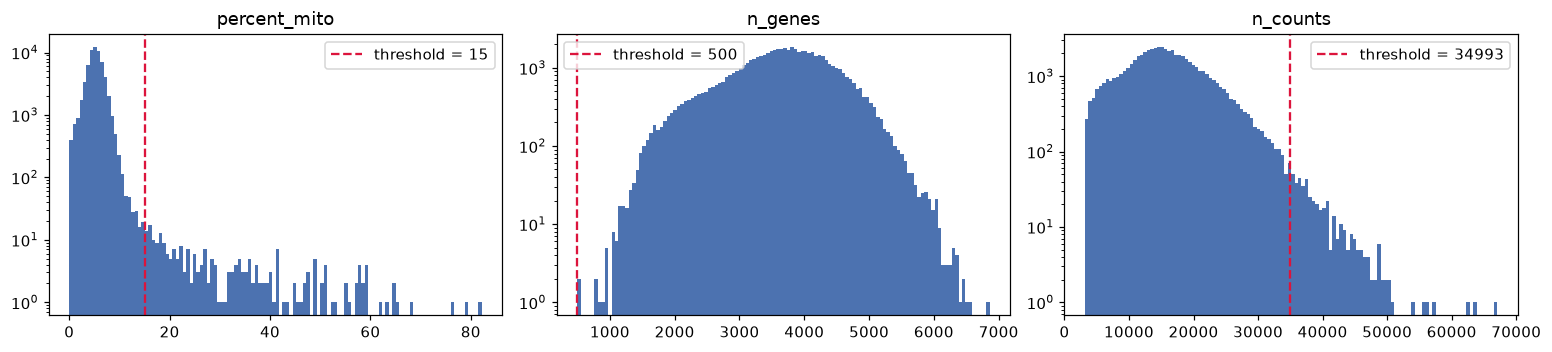

In [10]:
X = bt.adata.X
qc_df = pd.DataFrame({
    "n_counts": np.asarray(X.sum(axis=1)).ravel(),
    "n_genes": np.asarray((X > 0).sum(axis=1)).ravel(),
    "percent_mito": bt.adata.obs["percent_mito"].to_numpy(),
})
med = np.median(qc_df.n_counts)
mad = np.median(np.abs(qc_df.n_counts - med))
count_cap = med + PARAMS["max_counts_mad"] * mad
print(qc_df.describe().round(1))
print(f"\nCount cap = {med:.0f} + {PARAMS['max_counts_mad']} * {mad:.0f} = {count_cap:.0f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
for ax, (col, thr) in zip(axes, [("percent_mito", PARAMS["max_pct_mito"]),
                                 ("n_genes", PARAMS["min_genes"]),
                                 ("n_counts", count_cap)]):
    ax.hist(qc_df[col], bins=120, color="#4C72B0")
    ax.axvline(thr, color="crimson", ls="--", label=f"threshold = {thr:.0f}")
    ax.set_title(col); ax.set_yscale("log"); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
n_before = bt.adata.n_obs
bt.qc_cells(max_pct_mito=PARAMS["max_pct_mito"],
            min_genes=PARAMS["min_genes"],
            max_counts_mad=PARAMS["max_counts_mad"])
print(f"Kept {bt.adata.n_obs} / {n_before} cells ({100 * bt.adata.n_obs / n_before:.1f} %)")

Cell QC: mito>15.0%: 246, genes<500: 1, counts>34993: 463 -> removing 709 cells


Kept 61912 / 62621 cells (98.9 %)


## 5. Gene filter

Of the 32,738 annotated genes, many are never or almost never detected (e.g. non-coding RNAs, or
genes not expressed in K562). They carry no information, slow every step down, and make the HVG
estimates noisy. We keep genes detected in **at least 10 cells**.

**Exception: perturbation targets are always kept.** A target that CRISPRi silences efficiently
may be detected in very few cells. It still has to stay in the matrix: the knockdown check (step 6)
measures it, and GEARS also puts perturbed genes back into the gene set.

In [12]:
targets = set(bt.adata.obs["gene"].astype(str)) - {adamson.CTRL}
n_genes_before = bt.adata.n_vars
bt.quality_control(min_cells=PARAMS["min_cells_per_gene"], protect_genes=targets)
print(f"Removed {n_genes_before - bt.adata.n_vars} genes; "
      f"all {len(targets)} targets kept: {targets <= set(bt.adata.var_names)}")

After QC: 61912 cells, 18192 genes
Removed 14546 genes; all 90 targets kept: True


## 6. Guide QC: did each guide actually work?

GenePert treats each gene as **one** perturbation with **one** mean response. That only makes sense if
(a) the guide really knocked its target down, and (b) different guides for the same gene cause the
same response. A guide that fails, e.g. one that doesn't repress its target, makes the cells look
like controls and pulls the gene's pseudo-bulk towards zero effect. That is label noise in the
training targets.

`adamson.guide_qc` computes two metrics per guide on CP10k-normalized data (counts scaled to 10,000
per cell, so cells with different library sizes are comparable):

**(a) Knockdown ratio**

$$\text{kd\_ratio}(g) = \frac{\text{mean CP10k of the target gene in cells with guide } g}{\text{mean CP10k of the target gene in control cells}}$$

CRISPRi typically represses the target by 70–95 %, i.e. ratio ≈ 0.05–0.3. A ratio
**> 0.7** (less than 30 % knockdown) counts as a **failed knockdown**. We compute it on the linear
scale (not log), so it reads directly as "fraction of expression left".

**(b) Sibling-guide agreement** (only for genes with ≥ 2 guides)

For each guide we compute its change from control, Δ = mean log1p(CP10k) of the guide − mean of
controls, using the genes that are well expressed in controls (mean log expression > 0.2), and
**excluding the target gene itself**. Otherwise the knockdown alone would create agreement. We then
correlate Δ with the cell-weighted pooled Δ of the gene's *other* guides. If the guides work, the
downstream responses should agree.

**Decision rule.** A guide is dropped if
- it **failed knockdown** (ratio > 0.7), **or**
- its knockdown **can't be measured** (ratio = NaN) **and** it **disagrees** with its sibling guides (r < 0.5).

Why disagreement alone is *not* enough: when a gene has two guides that disagree, the correlation
can't tell which one is wrong. And genes with weak downstream effects give noisy Δ profiles, so even
two working guides correlate poorly. With disagreement alone, guides with excellent knockdown would
be thrown out, e.g. GBF1 (target at ~35 % of control in both guides, r ≈ 0.29) or STT3A_pDS011 (27 %,
"disagreeing" only with a 1-cell sibling). The agreement values are still saved in `guide_qc.csv`.

We also check that the two control guide types have the same profile (Pearson r of their mean log
profiles). Only then is pooling them in step 3 safe.

In [13]:
qc, ctrl_r = adamson.guide_qc(bt.adata,
                              max_kd_ratio=PARAMS["max_kd_ratio"],
                              min_agreement_r=PARAMS["min_agreement_r"])
print(f"Control guides 63(mod) vs Gal4-4(mod): r = {ctrl_r:.4f}  -> pooling is safe")
print(f"Median knockdown ratio over all guides: {qc['kd_ratio'].median():.3f} "
      f"(~{100 * (1 - qc['kd_ratio'].median()):.0f} % knockdown)")
qc.round(3).head(15)

Control guides 63(mod) vs Gal4-4(mod): r = 0.9996  -> pooling is safe
Median knockdown ratio over all guides: 0.172 (~83 % knockdown)


,gene,n_cells,n_guides_for_gene,kd_ratio,agreement_r,failed_kd,disagrees,flagged
guide,,,,,,,,
AARS_pDS381,AARS,443,1,0.148,NaN,False,False,False
AMIGO3_pDS434,AMIGO3,709,1,0.000,NaN,False,False,False
ARHGAP22_pDS458,ARHGAP22,484,1,0.742,NaN,True,False,True
ASCC3_pDS052,ASCC3,1131,2,0.117,0.917,False,False,False
ASCC3_pDS051,ASCC3,605,2,0.163,0.917,False,False,False
ATF4_pBA608,ATF4,321,3,0.952,0.122,True,True,True
ATF4_pBA577,ATF4,22,3,1.084,0.111,True,True,True
ATF4_pBA576,ATF4,5,3,0.896,0.073,True,True,True
ATF6_pBA586,ATF6,10,1,0.239,NaN,False,False,False


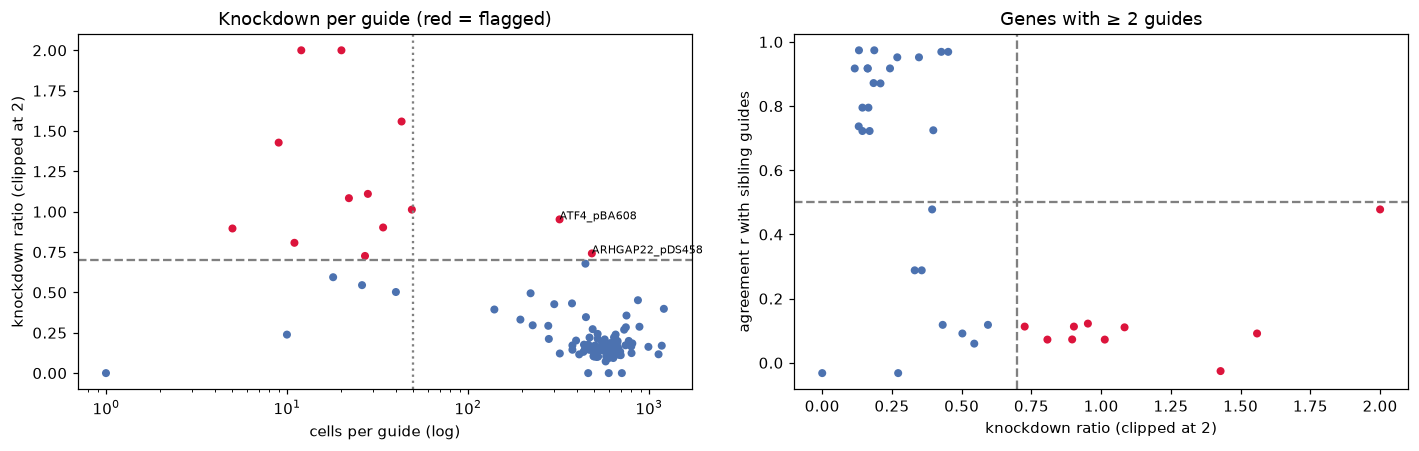

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
colors = np.where(qc["flagged"], "crimson", "#4C72B0")
ax.scatter(qc["n_cells"], qc["kd_ratio"].clip(upper=2), c=colors, s=18)
ax.axhline(PARAMS["max_kd_ratio"], ls="--", color="grey")
ax.axvline(PARAMS["min_cells_per_pert"], ls=":", color="grey")
ax.set_xscale("log"); ax.set_xlabel("cells per guide (log)"); ax.set_ylabel("knockdown ratio (clipped at 2)")
ax.set_title("Knockdown per guide (red = flagged)")
for g, row in qc[qc["flagged"] & (qc["n_cells"] > 100)].iterrows():
    ax.annotate(g, (row["n_cells"], min(row["kd_ratio"], 2)), fontsize=7)

ax = axes[1]
multi = qc.dropna(subset=["agreement_r"])
ax.scatter(multi["kd_ratio"].clip(upper=2), multi["agreement_r"],
           c=np.where(multi["flagged"], "crimson", "#4C72B0"), s=18)
ax.axhline(PARAMS["min_agreement_r"], ls="--", color="grey")
ax.axvline(PARAMS["max_kd_ratio"], ls="--", color="grey")
ax.set_xlabel("knockdown ratio (clipped at 2)"); ax.set_ylabel("agreement r with sibling guides")
ax.set_title("Genes with ≥ 2 guides")
plt.tight_layout(); plt.show()

In [15]:
flagged = qc.index[qc["flagged"]].tolist()
print(f"{len(flagged)} flagged guides:")
qc.loc[flagged, ["gene", "n_cells", "n_guides_for_gene", "kd_ratio", "agreement_r",
                 "failed_kd", "disagrees"]].round(3)

13 flagged guides:


,gene,n_cells,n_guides_for_gene,kd_ratio,agreement_r,failed_kd,disagrees
guide,,,,,,,
ARHGAP22_pDS458,ARHGAP22,484,1,0.742,NaN,True,False
ATF4_pBA608,ATF4,321,3,0.952,0.122,True,True
ATF4_pBA577,ATF4,22,3,1.084,0.111,True,True
ATF4_pBA576,ATF4,5,3,0.896,0.073,True,True
C7orf26_pDS004,C7orf26,12,1,2.186,NaN,True,False
EIF2AK3_pBA573,EIF2AK3,20,2,3.505,0.478,True,True
ERN1_pBA575,ERN1,43,2,1.559,0.091,True,True
PSMA1_pDS007,PSMA1,28,1,1.110,NaN,True,False
PSMD12_pDS008,PSMD12,49,2,1.013,0.072,True,True


**How to read this table.** Most flagged guides belong to the small, late-added UPR-sensor
guides (`pBA…` plasmids: ATF4, XBP1, ERN1, EIF2AK3) or are tiny groups whose ratio is just noise
(e.g. YIPF5_pDS001 with 9 cells). Two large guides fail clearly: **ARHGAP22_pDS458** (target at 74 % of
control, 484 cells) and **ATF4_pBA608** (95 %, 321 cells). This matches what the study notes found
when inspecting the file.

> ⚠️ Several UPR master regulators (ATF4, XBP1, ERN1, ATF6) lose all their cells in this step and
> the next. The Adamson screen was built around these genes, so it's worth reporting results
> both ways. Set `keep_failed_kd=True` (CLI: `--keep-failed-kd`) to keep flagged guides.

In [16]:
qc["kept"] = ~qc["flagged"] | PARAMS["keep_failed_kd"]
if not PARAMS["keep_failed_kd"] and flagged:
    bt.adata = adamson.drop_guides(bt.adata, flagged)

Dropping 13 flagged guides (1065 cells)


## 7. Merge guides into genes; minimum cells per perturbation

After the guide QC, all remaining guides of a gene are considered to give the same perturbation,
so from here on we work only with `obs['gene']`. This happens implicitly: `gene` is what becomes
the `condition` label.

We then require **≥ 50 cells per gene**. A pseudo-bulk mean over very few cells is noisy. In ridge
regression every perturbation counts as one training row with equal weight, so a noisy 20-cell
mean would count as much as a clean 800-cell mean. The notes suggest 30–50; we use 50 (as
cautious as GEARS, which has 300–700 cells per perturbation on average).

Dropping 2 genes with < 50 cells: ['ATF6', 'ERN1']



82 perturbed genes + ctrl remain
count      82.0
mean      654.0
std       316.0
min       140.0
25%       494.0
50%       600.0
75%       675.0
max      1813.0


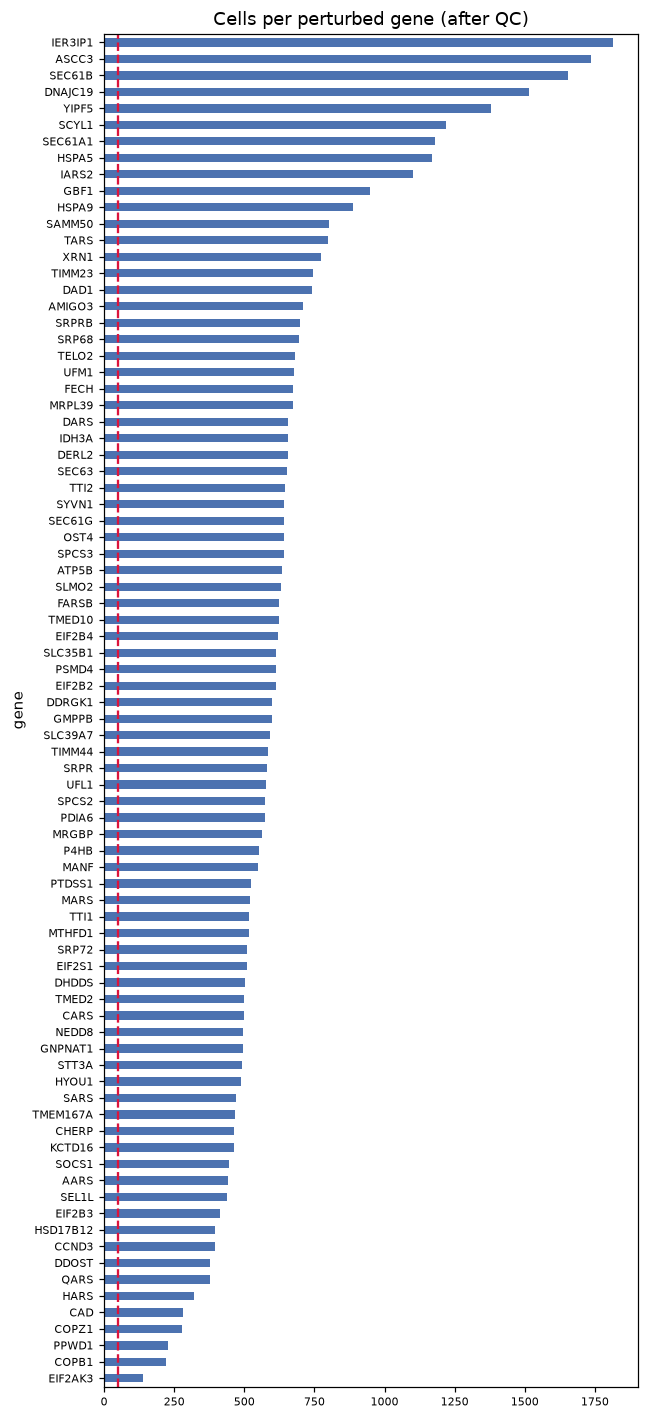

In [17]:
bt.adata, small = adamson.filter_min_cells(bt.adata, min_cells=PARAMS["min_cells_per_pert"])
qc.loc[qc["gene"].isin(small), "kept"] = False

sizes = bt.adata.obs["gene"].value_counts()
print(f"\n{len(sizes) - 1} perturbed genes + ctrl remain")
print(sizes.drop("ctrl").describe().round(0).to_string())

ax = sizes.drop("ctrl").sort_values().plot.barh(figsize=(6, 13), color="#4C72B0", fontsize=7)
ax.axvline(PARAMS["min_cells_per_pert"], ls="--", color="crimson")
ax.set_title("Cells per perturbed gene (after QC)"); plt.tight_layout(); plt.show()

## 8. Update gene symbols to current HGNC names

The file uses the **older hg19 / 10x annotation**. Several perturbed genes have been renamed by HGNC
since then (e.g. the aminoacyl-tRNA synthetases got a `1` suffix: `TARS` → `TARS1`; `C7orf26` → `INTS15`).

Why this matters: GenePert looks up the embedding of each perturbed gene **by name**
(`self.embeddings[gene_name]`, `populate_X_y`). Current embedding files (GenePT / NCBI summaries,
GenePT-Revisited) use current symbols, so an old name would be **silently skipped**: that
perturbation would just disappear from training and testing.

We rename the genes in both `var_names` and `obs['gene']`, so the expression columns and the labels
stay consistent, and keep the original symbol in `var['symbol_orig']`. If your embedding file uses
the old names, set `harmonize=False` (CLI: `--no-harmonize`).

In [18]:
pd.Series(adamson.GENE_ALIASES, name="current HGNC").rename_axis("old symbol").to_frame()

,current HGNC
old symbol,
AARS,AARS1
ATP5B,ATP5F1B
C7orf26,INTS15
CARS,CARS1
DARS,DARS1
HARS,HARS1
MARS,MARS1
QARS,QARS1
SARS,SARS1


In [19]:
if PARAMS["harmonize"]:
    bt.adata = adamson.harmonize_symbols(bt.adata)
    qc["gene_hgnc"] = qc["gene"].map(lambda g: adamson.GENE_ALIASES.get(g, g))

Renamed 11 genes to current HGNC symbols: ['AARS', 'ATP5B', 'C7orf26', 'CARS', 'DARS', 'HARS', 'MARS', 'QARS', 'SARS', 'SLMO2', 'TARS']


## 9. Pick highly variable genes (HVGs) without leakage

GenePert predicts **5,000 HVGs** instead of all ~18k genes. Most genes barely change
and only add noise to the regression and the metrics.

**The leakage problem.** If we picked HVGs on *all* cells, the gene set would depend on the
responses of the **test** perturbations. A gene that a test perturbation strongly changes would be
picked *because of* that test perturbation, which leaks test information into the setup. GenePert
evaluates on held-out perturbations (5-fold CV over genes), so this matters.

**Our fix:** pick HVGs on **control cells only**. This gene set doesn't depend on any perturbation,
so it is valid for every CV split and we don't need to re-preprocess per fold.

Details:
- **Method `seurat_v3`**: models the mean–variance relationship of **raw counts** (variance-stabilized
  with a loess fit) and ranks genes by standardized variance. It needs counts, so it runs **before**
  normalization (`scikit-misc` must be installed).
- **Add back the perturbed genes** that aren't HVGs (as GEARS does). The knockdown of the target
  itself is often the strongest single effect, and evaluation (or excluding the target from the
  metrics) needs that column.
- We only *choose* the genes here. The subset is applied **after** normalization (step 10), so
  library sizes are computed over all genes, as GEARS describes ("normalize by total counts over
  all genes").

In [20]:
perturbed = [g for g in bt.adata.obs["gene"].cat.categories if g != adamson.CTRL]
bt.select_hvgs(n_top_genes=PARAMS["n_hvg"], column="gene", ctrl_label=adamson.CTRL,
               control_only=True, add_genes=perturbed)

added = [g for g in perturbed if not bt.adata.var.loc[g, "highly_variable"]]
print(f"Perturbed genes already HVG: {len(perturbed) - len(added)}, added back: {len(added)}")

HVGs: 5000 + 62 added perturbed genes = 5062
Perturbed genes already HVG: 20, added back: 62


## 10. Normalize, log-transform, subset genes

1. **Library-size normalization to 10,000 counts per cell** (CP10k). Cells differ in sequencing
   depth (here ~3k–35k UMIs). Dividing by each cell's total and multiplying by 10,000 makes
   expression comparable between cells. 10,000 is the GenePT/GenePert/Scanpy standard; the old
   project code used 1e6 (CPM), which with log1p squeezes low values differently and wouldn't match
   the paper.
2. **`log1p`** = log(1 + x). This stabilizes the variance (in count data, variance grows with the
   mean) and makes fold-changes additive. The model's Δ-from-control then reads as an approximate
   log-fold-change.
3. **Subset** to the HVG + target genes from step 9. The raw counts of these genes are kept in
   `layers['counts']`, e.g. for DE testing or other normalizations later.

**Not done on purpose:**
- **No batch correction.** This is a single 10x run (GSM2406681); there is no batch to correct, and
  correction could remove real perturbation effects.
- **No z-scaling** (`sc.pp.scale`) before pseudo-bulking. GenePert models mean log-expression; scaling
  would change the target and blow up noisy low-expression genes.

In [21]:
bt.normalize(target_sum=PARAMS["target_sum"])
bt.log_transform()
bt.subset_genes(keep_counts_layer=True)
print(bt.adata)

print("\nlog1p range:", float(bt.adata.X.min()), "-", float(bt.adata.X.max()))

AnnData object with n_obs × n_vars = 60797 × 5062
    obs: 'perturbation', 'read count', 'UMI count', 'tissue_type', 'cell_line', 'cancer', 'disease', 'perturbation_type', 'celltype', 'organism', 'ncounts', 'ngenes', 'percent_mito', 'percent_ribo', 'nperts', 'guide', 'gene'
    var: 'ensembl_id', 'ncounts', 'ncells', 'symbol_orig', 'highly_variable'
    uns: 'log1p'
    layers: None (.X), 'counts'

log1p range: 0.0 - 7.60938024520874


## 11. Build GenePert `condition` labels

GenePert (and GEARS) use one string per perturbation: `GENE+ctrl` for a single-gene perturbation
(the `+ctrl` is the "empty" second slot of a possible double perturbation) and `ctrl` for controls.
GenePert's `clean_condition` strips `+ctrl` to get the gene name, and `get_mean_control` looks up
`condition == 'ctrl'`.

In [22]:
bt.set_condition(gene_column="gene", ctrl_label=adamson.CTRL)
bt.adata.obs[["guide", "gene", "condition"]].drop_duplicates("condition").head(8)

,guide,gene,condition
cell_barcode,,,
AAACATACAAGATG,63(mod)_pBA580,ctrl,ctrl
AAACATACACCTAG,OST4_pDS353,OST4,OST4+ctrl
AAACATACTTCCCG,SEC61A1_pDS031,SEC61A1,SEC61A1+ctrl
AAACATTGAAACAG,EIF2B4_pDS491,EIF2B4,EIF2B4+ctrl
AAACATTGCAGCTA,SRPR_pDS482,SRPR,SRPR+ctrl
AAACCGTGCTGTAG,IER3IP1_pDS002,IER3IP1,IER3IP1+ctrl
AAACCGTGTCGATG,YIPF5_pDS186,YIPF5,YIPF5+ctrl
AAACCGTGTTCCCG,HARS_pDS466,HARS1,HARS1+ctrl


## 12. Validate and build the training targets

`validate` (from `scripts/preprocess_adamson.py`) checks the cell-level output contract:
- labels are only `ctrl` / `*+ctrl`; ≥ 6,000 control cells; every condition has ≥ 50 cells;
- every perturbed gene is a column of `X`;
- `X` is finite and on a log scale (max < 15).

Then `bt.build_targets` collapses the cells into the **training targets** (the output of this whole
preprocessing stage). This is a small `AnnData`, **82 perturbations × 5,062 genes**:

| Field | Contents | Used for |
|---|---|---|
| `obs_names` | perturbed gene symbol (`SEC61A1`, not `SEC61A1+ctrl`) | the key into the embedding dictionary → row of the input matrix G |
| `X` | **mean log1p(CP10k) per perturbation** (pseudo-bulk) | GenePert's regression target **y** (what `populate_dicts` computes) |
| `layers['delta']` | `X − ctrl_mean`, the response from control (≈ log-fold-change) | the metrics (Pearson/MSE on Δ); also a valid target |
| `var['ctrl_mean']` | mean profile of the 7,206 control cells | turning Δ predictions back into absolute ones, centering in evaluation |
| `obs['n_cells']`, `obs['condition']` | cells per perturbation, original label | optional sample weights, joining back to the cell-level file |

Design choices:
- **Controls are not a training row.** `ctrl` has no gene to embed. GenePert's own k-fold puts
  `ctrl` into a fold and gives it a random embedding. Here it is a reference vector instead.
- **`X` or `delta`?** For ridge regression with an intercept they give the same predictions,
  because the two targets differ by one constant vector, which the intercept absorbs. Without an
  intercept, or for kNN/MLP, train on `delta` and evaluate on `delta`.
- **No leakage.** Every row is a mean over that perturbation's own cells, and `ctrl_mean` uses only
  control cells, so the file is valid for any split over perturbations. Split by **rows**.

`validate_targets` checks that the rows match the perturbations exactly, that all values are finite,
and that each perturbation lowers its own target gene.

In [23]:
adata_final = bt.adata
genes = validate(adata_final, PARAMS["min_cells_per_pert"])
print(f"Validation passed: {len(genes)} perturbations")

targets = bt.build_targets(column="condition", ctrl_label=adamson.CTRL)
on_target = validate_targets(targets, genes)
delta = targets.to_df(layer="delta")  # perturbations x genes, Δ from control
print(targets)
targets.obs.head()

Validation passed: 82 perturbations


AnnData object with n_obs × n_vars = 82 × 5062
    obs: 'condition', 'n_cells'
    var: 'ctrl_mean'
    layers: None (.X), 'delta'


,condition,n_cells
gene,,
AARS1,AARS1+ctrl,443
AMIGO3,AMIGO3+ctrl,709
ASCC3,ASCC3+ctrl,1736
ATP5F1B,ATP5F1B+ctrl,636
CAD,CAD+ctrl,280


### Sanity-check the targets

1. **On-target knockdown in the final data:** for each perturbation, the Δ of its own target gene
   should be clearly negative.
2. **Response structure:** correlating the perturbations' Δ profiles should show clusters of
   functionally related genes. Examples: ER translocation (SEC61A1/B/G, SRP, SRPR),
   N-glycosylation (DDOST, STT3A, OST4, DAD1), tRNA synthetases. These are the effects of the
   Adamson UPR screen, and the "similar genes → similar responses" structure is exactly the
   assumption GenePert relies on.

Target log-fold-change vs ctrl: median -0.30, 100% negative


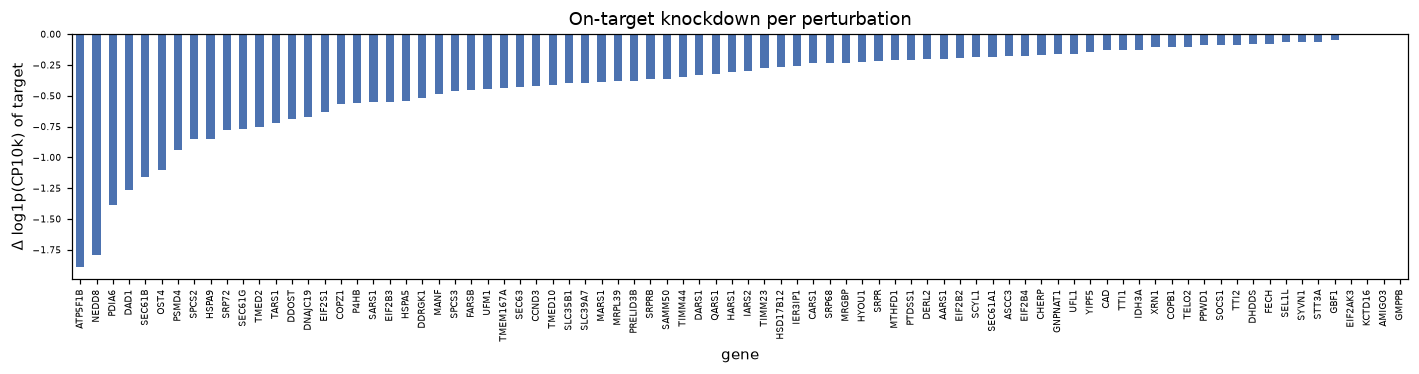

In [24]:
on_target = pd.Series(on_target, index=targets.obs_names).sort_values()
print(f"Target log-fold-change vs ctrl: median {on_target.median():.2f}, "
      f"{(on_target < 0).mean():.0%} negative")

fig, ax = plt.subplots(figsize=(13, 3.5))
on_target.plot.bar(ax=ax, color=np.where(on_target < 0, "#4C72B0", "crimson"), fontsize=6)
ax.set_ylabel("Δ log1p(CP10k) of target"); ax.set_title("On-target knockdown per perturbation")
plt.tight_layout(); plt.show()

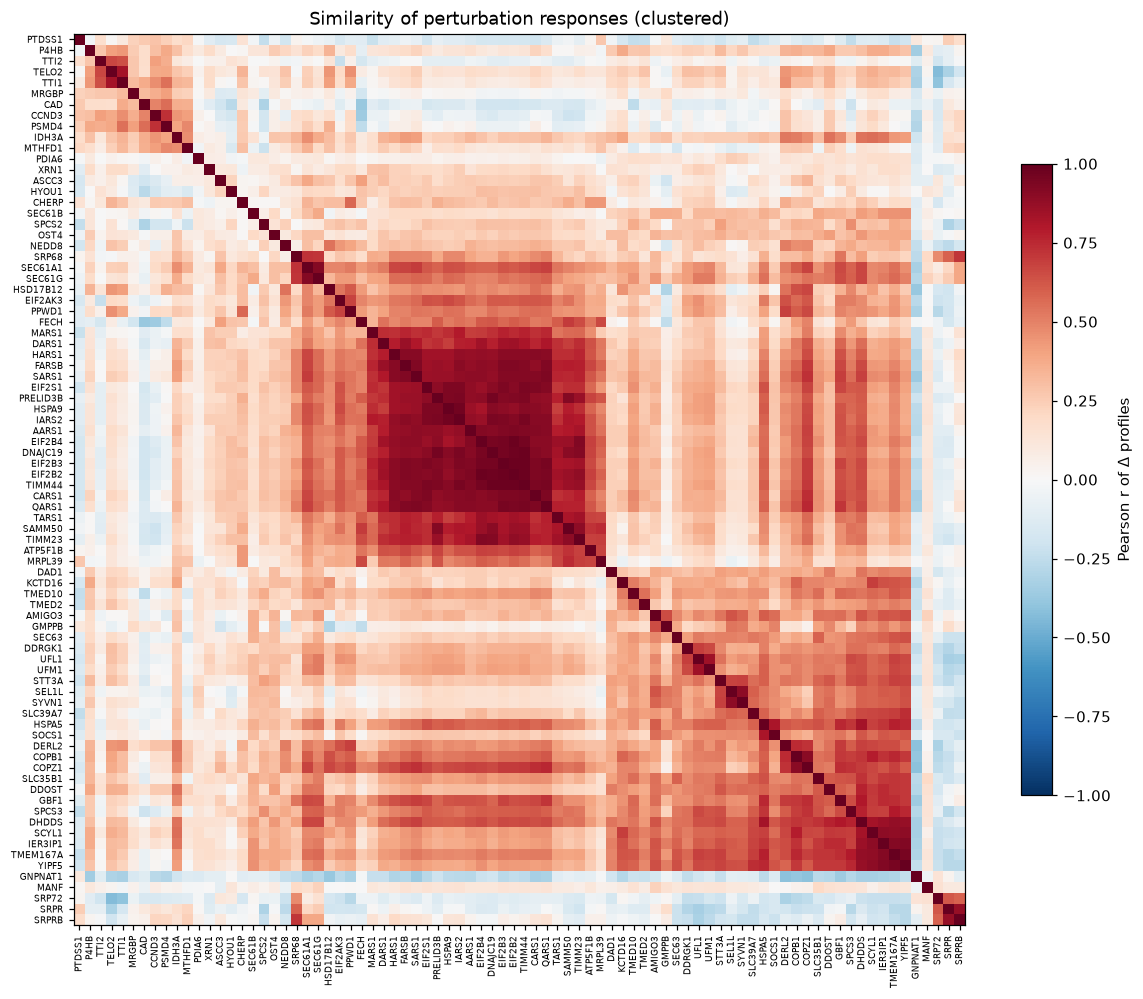

In [25]:
# Correlation of responses over the 500 genes that respond most across perturbations
top = delta.abs().mean().nlargest(500).index
corr = np.corrcoef(delta[top].to_numpy())
idx = leaves_list(linkage(delta[top].to_numpy(), "average", metric="correlation"))
names = delta.index[idx].tolist()

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(corr[np.ix_(idx, idx)], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=6)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.6, label="Pearson r of Δ profiles")
ax.set_title("Similarity of perturbation responses (clustered)")
plt.tight_layout(); plt.show()

## 13. Save the outputs

Outputs go to `data/processed/` (git-ignored, because they're large and reproducible):

| File | Contents |
|---|---|
| **`adamson_targets.h5ad`** | **training targets** (step 12): 82 × 5,062, `X` = mean log1p(CP10k), `layers['delta']`, `var['ctrl_mean']`, `obs['n_cells']`; ~7 MB. **This is what the training stage loads.** |
| `adamson_genepert.h5ad` | cell-level AnnData: `X` = log1p(CP10k), `layers['counts']` = raw counts, `obs['condition']`, `obs['gene']`, `obs['guide']`, `var['symbol_orig']`, `var['highly_variable']`. Kept for the original `GenePertExperiment`, DE tests and re-pseudo-bulking. |
| `guide_qc.csv` | per-guide cell count, knockdown ratio, agreement r, flags, kept/dropped |

Both h5ad files store all parameters in `uns['preprocessing']`.

Finally we check both entry points: (a) the original `GenePertExperiment` class loads the cell-level
file and its own pseudo-bulk means match our targets; (b) the targets file alone gives the `(G, y)`
pair for training. We use dummy random embeddings; real embeddings come in the GenePert step.

In [26]:
adata_final.uns["preprocessing"] = {k: str(v) for k, v in PARAMS.items()}
targets.uns["preprocessing"] = adata_final.uns["preprocessing"]
out = PARAMS["output"]
targets_path = out.with_name("adamson_targets.h5ad")

adata_final.write_h5ad(out)
qc.to_csv(out.with_name("guide_qc.csv"))
targets.write_h5ad(targets_path)
print("Wrote:", targets_path, out, out.with_name("guide_qc.csv"), sep="\n  ")

Wrote:
  /Users/vuhta/ML_Life_Sciences/data/processed/adamson_targets.h5ad
  /Users/vuhta/ML_Life_Sciences/data/processed/adamson_genepert.h5ad
  /Users/vuhta/ML_Life_Sciences/data/processed/guide_qc.csv


In [27]:
from GenePertExperiment import GenePertExperiment, populate_dicts

rng = np.random.default_rng(0)
dummy_embeddings = {g: rng.normal(size=64) for g in genes}

# (a) the original GenePert class on the cell-level file
exp = GenePertExperiment(dummy_embeddings)
exp.load_dataset(out)
print("Control mean vector:", exp.mean_expression.shape)
cond_genes = {exp.clean_condition(c) for c in exp.adata.obs["condition"].unique() if c != "ctrl"}
print("Perturbations with an embedding:", len(cond_genes & set(dummy_embeddings)), "/", len(cond_genes))
gp_means = {}
populate_dicts(exp.adata[exp.adata.obs["condition"] == "SEC61A1+ctrl"], gp_means)
print("GenePert mean == our target (SEC61A1):",
      np.allclose(np.asarray(gp_means["SEC61A1"]).ravel(), targets["SEC61A1"].X.ravel(), atol=1e-5))

# (b) the targets file alone is enough to train
t = ad.read_h5ad(targets_path)
G = np.stack([dummy_embeddings[g] / np.linalg.norm(dummy_embeddings[g]) for g in t.obs_names])
y = t.X                   # GenePert target (absolute); t.layers["delta"] for the response
print("Training pair: G", G.shape, " y", y.shape)

/Users/vuhta/ML_Life_Sciences/genepert/GenePertExperiment.py:104: FutureWarning: Import from `scanpy.io` instead
  self.adata = sc.read_h5ad(dataset_path)


Control mean vector: (5062,)
Perturbations with an embedding: 82 / 82
GenePert mean == our target (SEC61A1): True
Training pair: G (82, 64)  y (82, 5062)


## Part 1 summary

In [28]:
summary = pd.Series({
    "raw cells": 65337,
    "final cells": adata_final.n_obs,
    "control cells": int((adata_final.obs["condition"] == "ctrl").sum()),
    "raw genes": 32738,
    "final genes (HVG + targets)": adata_final.n_vars,
    "guides in raw data (non-control)": int(len(qc)),
    "guides dropped (QC + min cells)": int((~qc["kept"]).sum()),
    "perturbed genes (final)": len(genes),
    "median cells per perturbation": int(adata_final.obs["condition"].value_counts().drop("ctrl").median()),
})
summary.to_frame("value")

,value
raw cells,65337
final cells,60797
control cells,7206
raw genes,32738
final genes (HVG + targets),5062
guides in raw data (non-control),110
guides dropped (QC + min cells),15
perturbed genes (final),82
median cells per perturbation,600


### Key decisions and open points

1. **Guide QC removes 8 of the 90 genes**: ARHGAP22, INTS15 (C7orf26), PSMA1 (failed knockdown),
   PSMD12, XBP1, ATF4 (all guides failed), and ERN1 and ATF6 (< 50 cells). This leaves 82
   perturbations, against 87 in the GEARS version. Report the main results with the default settings
   and, as a robustness check, with `keep_failed_kd=True`.
2. **HVGs come from control cells only**, so there's no leakage into CV folds. GEARS/GenePert chose
   HVGs on all cells, so absolute numbers may differ slightly from the paper.
3. **Gene symbols are current HGNC.** Check that your embedding dictionary uses the same convention
   (`harmonize=False` otherwise).
4. **Evaluation tips** (from the notes): use Pearson correlation of **Δ from control** (raw profiles
   correlate at ~0.99 anyway), exclude the perturbed gene itself from per-perturbation metrics, and
   also report top-20 DE genes. Part 2 quantifies why (sections 15 and 18).
5. **Optional extensions not applied:** Mixscape (removes cells that escaped knockdown; hurts
   comparability with the paper), Scrublet doublet detection.
6. **Sanity check still to do:** correlate our Δ pseudo-bulks with the GEARS-processed Adamson for the
   shared perturbations (`cell-gears`: `PertData(...).load(data_name='adamson')`).

# Part 2 · Gene-level analysis of the training targets

Part 1 produced the training targets (`data/processed/adamson_targets.h5ad`). This part looks at the **genes** behind those targets before any model is trained. Two kinds of
genes play different roles:

| Genes | How many | Role in GenePert |
|---|---|---|
| **readout genes** | 5,062 (columns) | what the model **predicts**: one value per gene per perturbation |
| **perturbed genes** | 82 (rows) | what the model gets as **input**, via the LLM embedding of the gene |

Questions (sections 15–19):

1. **Readout genes:** how well expressed are the genes we predict? How sparse are they?
2. **Which readout genes respond?** Is there a shared response across perturbations?
3. **Which perturbations have an effect?** How many differentially expressed (DE) genes each one has.
4. **How well can a model do at all?** The noise ceiling vs. the trivial "predict the training mean" baseline.
5. **How many independent response patterns are there?** PCA of the Δ profiles.

Outputs (in `data/processed/`): `readout_gene_stats.csv`, `perturbation_stats.csv`,
`top20_de_genes.json`. The functions are in `src/analysis/gene_stats.py`.

In [29]:
# Part 2 settings: DE thresholds and chart style (palette: categorical slots in fixed order,
# one sequential hue, blue <-> red diverging around a gray midpoint)
PROCESSED = PARAMS["output"].parent
DE_PADJ, DE_MIN_LOG2FC = 0.05, 0.5   # DE gene = BH-adjusted p < 0.05 and |log2FC| >= 0.5

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
NEUTRAL, INK, INK2 = "#b8b7b2", "#0b0b0b", "#52514e"
DIVERGING = LinearSegmentedColormap.from_list(
    "delta", ["#184f95", "#6da7ec", "#f0efec", "#ef8f8e", "#b52e2e"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "font.size": 9,
})


def place_labels(ax, xs, ys, names, prefer="left", fontsize=7, avoid=None):
    # Label points without text overlapping: try a few offsets per label, skip a label if none
    # fit. Call after the layout is final (tight_layout), since offsets are in screen points.
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    sides = [(5, "left"), (-5, "right")] if prefer == "left" else [(-5, "right"), (5, "left")]
    offsets = [(dx, dy, ha) for dy in (2, -9, 11, -18, 20) for dx, ha in sides]
    placed, skipped = [], []
    if avoid is not None:  # (x, y) of all points: labels must not cover them either
        for px, py in ax.transData.transform(np.column_stack(avoid)):
            placed.append(Bbox.from_extents(px - 3, py - 3, px + 3, py + 3))
    for x, y, name in zip(xs, ys, names):
        for dx, dy, ha in offsets:
            t = ax.annotate(name, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha,
                            fontsize=fontsize, color=INK)
            bb = t.get_window_extent(renderer).expanded(1.04, 1.1)
            inside = ax.bbox.x0 <= bb.x0 and bb.x1 <= ax.bbox.x1 and ax.bbox.y0 <= bb.y0 and bb.y1 <= ax.bbox.y1
            if inside and not any(bb.overlaps(p) for p in placed):
                placed.append(bb)
                break
            t.remove()
        else:
            skipped.append(name)
    return skipped

## 14. Differential expression vs. control

We reuse the cell-level data (`adata_final`) and the `targets` from Part 1. DE and the noise
ceiling need single cells, the other statistics only the targets.

**DE test.** Each perturbation's cells against the 7,206 control cells, gene by gene, with the
**Wilcoxon rank-sum test** on log1p(CP10k) (`scanpy.tl.rank_genes_groups`). Wilcoxon makes no
normality assumption, which matters for sparse single-cell counts. p-values are BH-adjusted per
perturbation. With hundreds of cells per group, tiny shifts become significant, so a DE gene also
needs an effect size of **|log2 fold-change| ≥ 0.5** (≈ 1.4×). Genes are ranked by |score|; the top 20
per perturbation are the standard "top-20 DE" gene set for evaluation (as in GEARS/GenePert).

In [30]:
adata = adata_final  # cell-level data from Part 1 (also frees the raw matrix held by `adata`)
print(f"cells: {adata.n_obs:,} | targets: {targets.n_obs} perturbations x {targets.n_vars:,} readout genes")

de = gs.differential_expression(adata, method="wilcoxon")
sig = gs.significant_de(de, padj=DE_PADJ, min_abs_log2fc=DE_MIN_LOG2FC)
top20 = gs.top_de_genes(de, n=20)

genes_stats = gs.readout_gene_stats(adata, targets, sig)
pert_stats = gs.perturbation_stats(adata, targets, sig, n_splits=10, seed=0)
delta = targets.to_df(layer="delta")
print(f"DE tests: {len(de):,} | significant: {len(sig):,}")

cells: 60,797 | targets: 82 perturbations x 5,062 readout genes


DE tests: 415,084 | significant: 17,174


### Headline numbers

In [31]:
headline = pd.Series({
    "readout genes": f"{len(genes_stats):,}",
    "  of which HVGs / added-back perturbed genes":
        f"{int(genes_stats.is_hvg.sum()):,} / {int((genes_stats.is_perturbed & ~genes_stats.is_hvg).sum())}",
    "median detection rate in control cells": f"{genes_stats.ctrl_detection.median():.0%}",
    "readout genes detected in < 10 % of control cells": f"{(genes_stats.ctrl_detection < 0.1).mean():.0%}",
    "readout genes DE in >= 1 perturbation": f"{(genes_stats.n_perts_de > 0).mean():.0%}",
    "median downstream DE genes per perturbation": f"{pert_stats.n_de_downstream.median():.0f}",
    "perturbations with < 10 downstream DE genes": f"{(pert_stats.n_de_downstream < 10).sum()} / {len(pert_stats)}",
    "median noise ceiling (Pearson Δ)": f"{pert_stats.noise_ceiling.median():.2f}",
    "median mean-baseline r (Pearson Δ)": f"{pert_stats.mean_baseline_r.median():.2f}",
})
headline.to_frame("value")

,value
readout genes,"5,062"
of which HVGs / added-back perturbed genes,"5,000 / 62"
median detection rate in control cells,12%
readout genes detected in < 10 % of control cells,47%
readout genes DE in >= 1 perturbation,49%
median downstream DE genes per perturbation,52
perturbations with < 10 downstream DE genes,24 / 82
median noise ceiling (Pearson Δ),0.95
median mean-baseline r (Pearson Δ),0.44


## 15. Readout genes: expression and sparsity

The readout genes are the 5,000 HVGs picked on control cells plus the perturbed genes added back.
Two properties matter for the model:

- **Detection rate** (fraction of control cells with ≥ 1 UMI). A gene seen in 2 % of cells has a
  pseudo-bulk mean built from a handful of non-zero values, so its Δ is mostly sampling noise.
- **Mean |Δ| vs. expression.** Where does the perturbation signal live: in well-expressed or in
  sparse genes?

Note: GenePert's Pearson Δ metric weighs all 5,062 genes equally, so many near-silent genes dilute it.

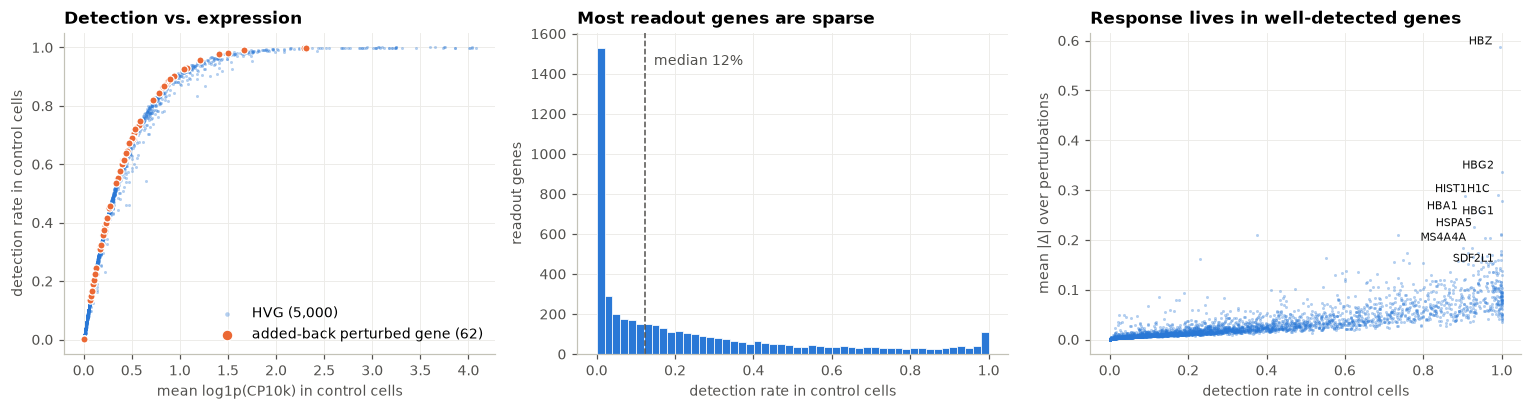

,genes,median_mean_abs_delta,share_DE_somewhere
ctrl_detection,,,
"(-0.001, 0.1]",2363,0.002,0.111
"(0.1, 0.5]",1780,0.016,0.799
"(0.5, 0.9]",664,0.048,0.858
"(0.9, 1.0]",244,0.088,0.852


In [32]:
g = genes_stats
added = g.is_perturbed & ~g.is_hvg
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

ax = axes[0]
ax.scatter(g.loc[~added, "ctrl_mean_log"], g.loc[~added, "ctrl_detection"], s=4, c=BLUE, alpha=0.35,
           lw=0, label=f"HVG ({(~added).sum():,})")
ax.scatter(g.loc[added, "ctrl_mean_log"], g.loc[added, "ctrl_detection"], s=22, c=ORANGE,
           edgecolor="white", lw=0.8, label=f"added-back perturbed gene ({added.sum()})")
ax.set_xlabel("mean log1p(CP10k) in control cells"); ax.set_ylabel("detection rate in control cells")
ax.set_title("Detection vs. expression"); ax.legend(loc="lower right", markerscale=1.5)

ax = axes[1]
ax.hist(g.ctrl_detection, bins=50, color=BLUE, edgecolor="white", lw=0.5)
ax.axvline(g.ctrl_detection.median(), color=INK2, ls="--", lw=1)
ax.annotate(f"median {g.ctrl_detection.median():.0%}", (g.ctrl_detection.median(), ax.get_ylim()[1] * 0.9),
            xytext=(6, 0), textcoords="offset points", color=INK2)
ax.set_xlabel("detection rate in control cells"); ax.set_ylabel("readout genes")
ax.set_title("Most readout genes are sparse")

ax = axes[2]
ax.scatter(g.ctrl_detection, g.mean_abs_delta, s=4, c=BLUE, alpha=0.35, lw=0)
ax.set_xlabel("detection rate in control cells"); ax.set_ylabel("mean |Δ| over perturbations")
ax.set_title("Response lives in well-detected genes")
plt.tight_layout()
top = g.nlargest(8, "mean_abs_delta")
place_labels(ax, top.ctrl_detection, top.mean_abs_delta, top.index, prefer="right")
plt.show()

bins = pd.cut(g.ctrl_detection, [0, 0.1, 0.5, 0.9, 1.0], include_lowest=True)
g.groupby(bins, observed=True).agg(genes=("mean_abs_delta", "size"),
                                   median_mean_abs_delta=("mean_abs_delta", "median"),
                                   share_DE_somewhere=("n_perts_de", lambda s: (s > 0).mean())).round(3)

## 16. Which readout genes respond?

We rank readout genes by their **mean |Δ| across all 82 perturbations** (a gene that responds to many
perturbations, or strongly to some) and show the top 40 as a clustered heatmap (perturbations ×
genes, blue = down, red = up vs. control).

What to look for: ER chaperones of the unfolded protein response (*HSPA5*, *HSP90B1*, *SDF2L1*,
*CALR*, *MANF*, *PDIA6*), amino-acid-response genes of the integrated stress response (e.g. *PHGDH*,
serine synthesis, an ATF4 target) and, since K562 is an erythroleukemia line, hemoglobin genes
(*HBZ*, *HBG1/2*, *HBA1*), which follow cell state and growth.

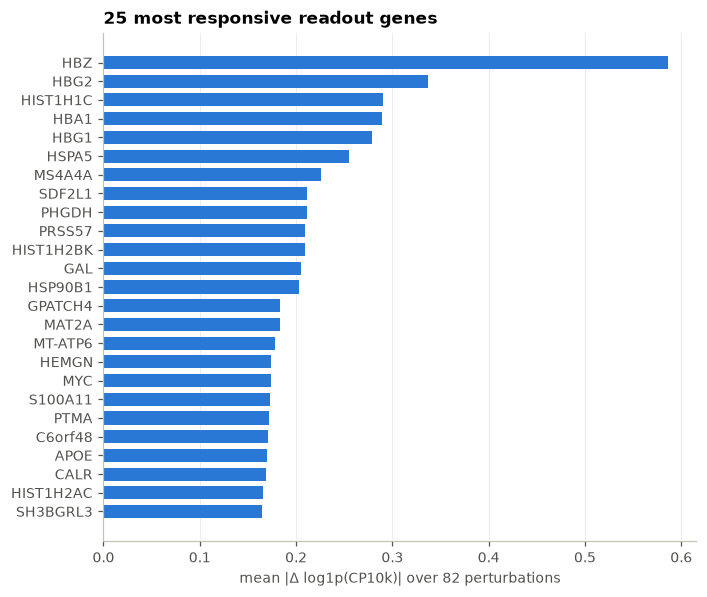

,ctrl_mean_log,ctrl_detection,mean_abs_delta,max_abs_delta,top_perturbation,n_perts_de
HBZ,3.857,0.997,0.586,2.154,CARS1,41
HBG2,4.074,1.000,0.337,1.227,CARS1,28
HIST1H1C,2.428,0.989,0.290,1.137,EIF2S1,29
HBA1,1.384,0.908,0.289,0.965,EIF2S1,36
HBG1,3.312,1.000,0.279,0.984,CARS1,25
HSPA5,1.318,0.944,0.255,1.075,DHDDS,29
MS4A4A,1.406,0.930,0.226,0.926,CARS1,26
SDF2L1,2.691,0.999,0.211,1.579,HSPA5,14
PHGDH,0.245,0.376,0.211,0.918,CARS1,35
PRSS57,0.644,0.735,0.210,0.812,EIF2B3,29


In [33]:
top_resp = g.nlargest(25, "mean_abs_delta").iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.barh(top_resp.index, top_resp.mean_abs_delta, color=BLUE, height=0.7)
ax.set_xlabel("mean |Δ log1p(CP10k)| over 82 perturbations"); ax.grid(axis="y", visible=False)
ax.set_title("25 most responsive readout genes")
plt.tight_layout(); plt.show()

g.nlargest(15, "mean_abs_delta")[["ctrl_mean_log", "ctrl_detection", "mean_abs_delta",
                                  "max_abs_delta", "top_perturbation", "n_perts_de"]].round(3)

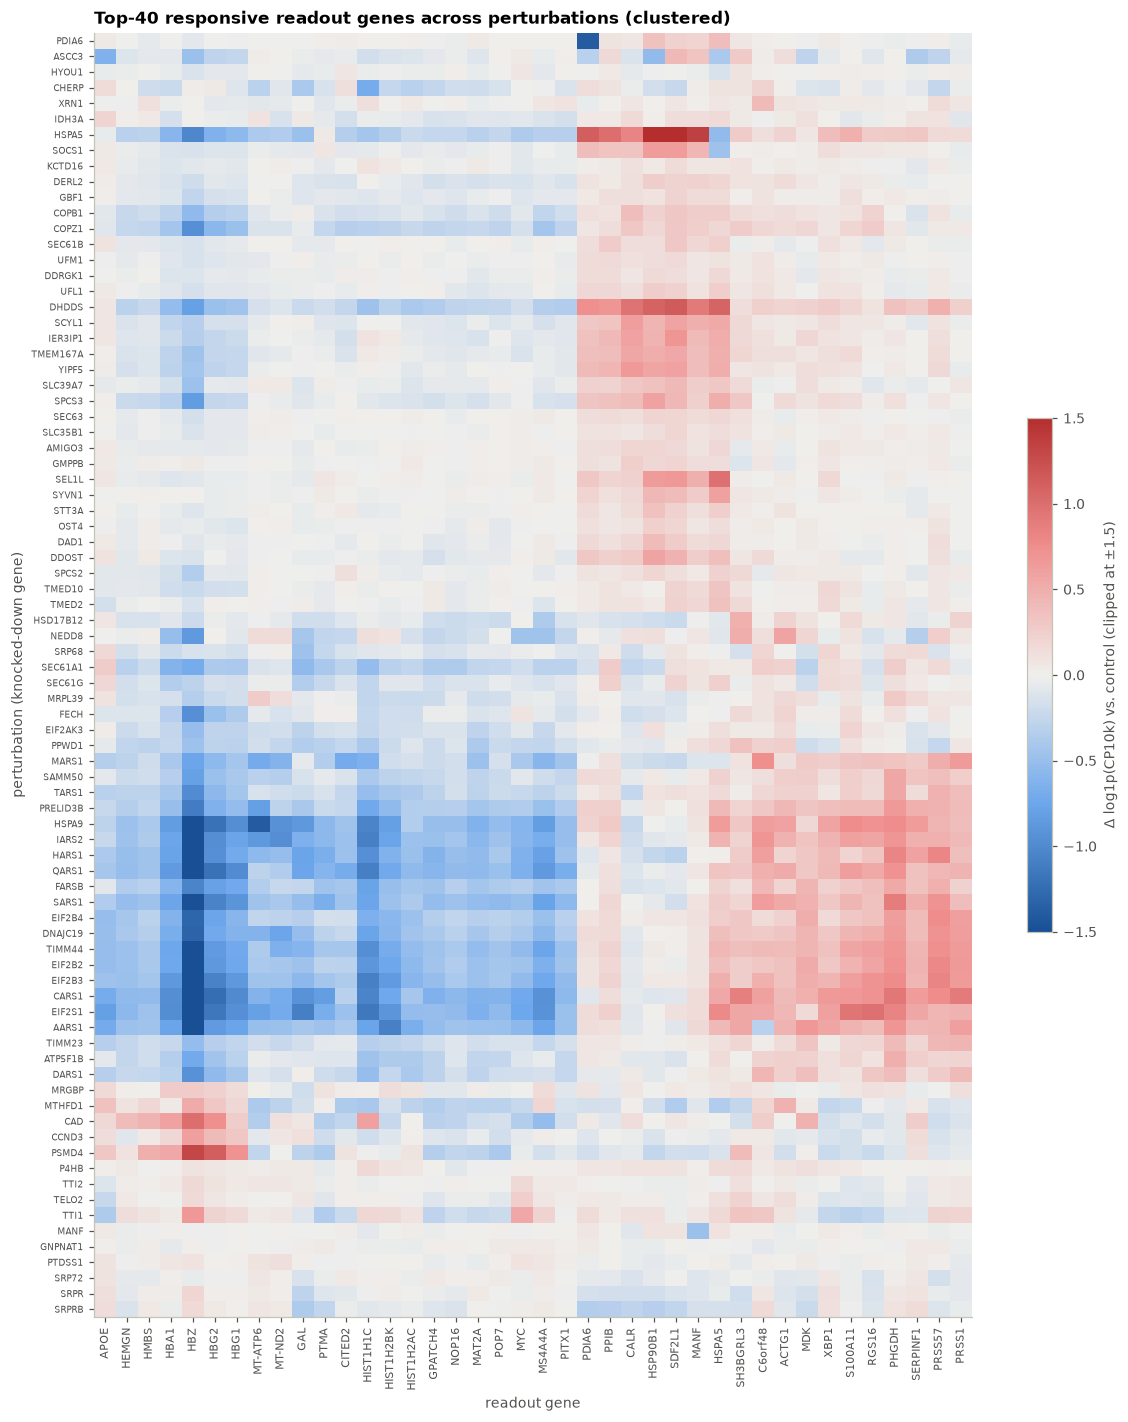

In [34]:
cols = g.nlargest(40, "mean_abs_delta").index
M = delta[cols]
row_order = leaves_list(linkage(M.to_numpy(), "average", metric="correlation"))
col_order = leaves_list(linkage(M.to_numpy().T, "average", metric="correlation"))
M = M.iloc[row_order, col_order]

lim = 1.5
fig, ax = plt.subplots(figsize=(11, 13))
im = ax.imshow(M.clip(-lim, lim), cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=90, fontsize=7)
ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=6)
ax.grid(False)
ax.set_xlabel("readout gene"); ax.set_ylabel("perturbation (knocked-down gene)")
fig.colorbar(im, ax=ax, shrink=0.4, label=f"Δ log1p(CP10k) vs. control (clipped at ±{lim})")
ax.set_title("Top-40 responsive readout genes across perturbations (clustered)")
plt.tight_layout(); plt.show()

## 17. Which perturbations have an effect?

For each perturbation we count the **downstream DE genes** (DE genes other than the knocked-down
gene itself). A perturbation with almost no downstream DE genes is a near-null: its true Δ is close to
zero, so Pearson Δ on it is mostly correlating noise. Those perturbations are worth flagging in the
evaluation.

The right panel checks that the DE count is not just a function of how many cells a perturbation
has. More cells give more statistical power, and that would make the count a measure of sample size
rather than biology.

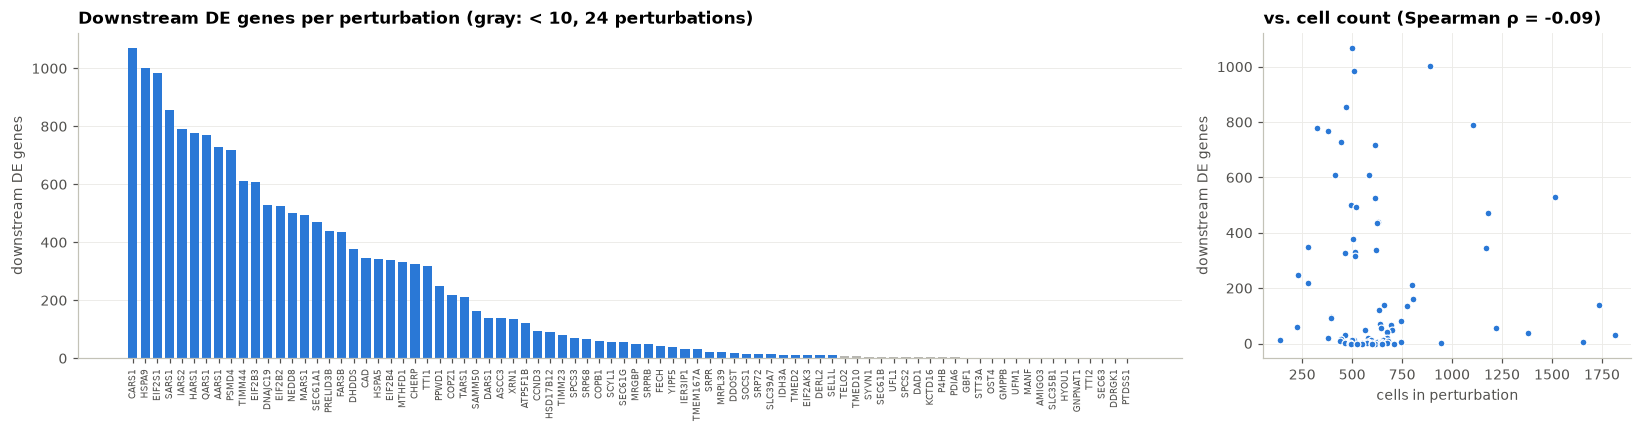

Perturbations with < 10 downstream DE genes: PTDSS1, DDRGK1, SEC63, TTI2, GNPNAT1, HYOU1, SLC35B1, AMIGO3, MANF, UFM1, GMPPB, OST4, STT3A, GBF1, PDIA6, P4HB, KCTD16, DAD1, SPCS2, UFL1, SEC61B, SYVN1, TMED10, TELO2


In [35]:
ps = pert_stats.sort_values("n_de_downstream", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})

ax = axes[0]
weak = ps.n_de_downstream < 10
ax.bar(ps.index, ps.n_de_downstream, color=np.where(weak, NEUTRAL, BLUE), width=0.75)
ax.set_xticks(range(len(ps))); ax.set_xticklabels(ps.index, rotation=90, fontsize=6)
ax.set_ylabel("downstream DE genes"); ax.grid(axis="x", visible=False)
ax.set_title(f"Downstream DE genes per perturbation (gray: < 10, {weak.sum()} perturbations)")

ax = axes[1]
ax.scatter(ps.n_cells, ps.n_de_downstream, s=20, c=BLUE, edgecolor="white", lw=0.8)
rho = ps[["n_cells", "n_de_downstream"]].corr(method="spearman").iloc[0, 1]
ax.set_xlabel("cells in perturbation"); ax.set_ylabel("downstream DE genes")
ax.set_title(f"vs. cell count (Spearman ρ = {rho:.2f})")
plt.tight_layout(); plt.show()

print("Perturbations with < 10 downstream DE genes:", ", ".join(ps.index[weak][::-1]))

## 18. How well can a model do? Noise ceiling vs. mean baseline

GenePert scores a prediction by the **Pearson correlation between predicted and observed Δ**.
Two reference points tell us what that number means for each perturbation:

**Noise ceiling (upper bound).** The observed Δ is itself a noisy estimate (a mean over a few hundred
cells). We split each perturbation's cells, and the control cells, into random halves, compute Δ in
each half and correlate the two (`split_half_r`, averaged over 10 splits). The Spearman–Brown formula
turns that into the reliability of the full-size Δ, and **√reliability** is the highest Pearson r that
even a perfect model can get against the observed Δ.

**Mean baseline (lower bound).** Many perturbations share one stress response. A model that ignores
the embedding and always predicts the **average Δ of the training perturbations** already scores well
on those. We compute it leave-one-out: each perturbation's Δ against the mean Δ of the other 81.

**Headroom = ceiling − baseline** is what the gene embedding has to explain. A model's average Pearson
Δ only means something next to these two numbers.

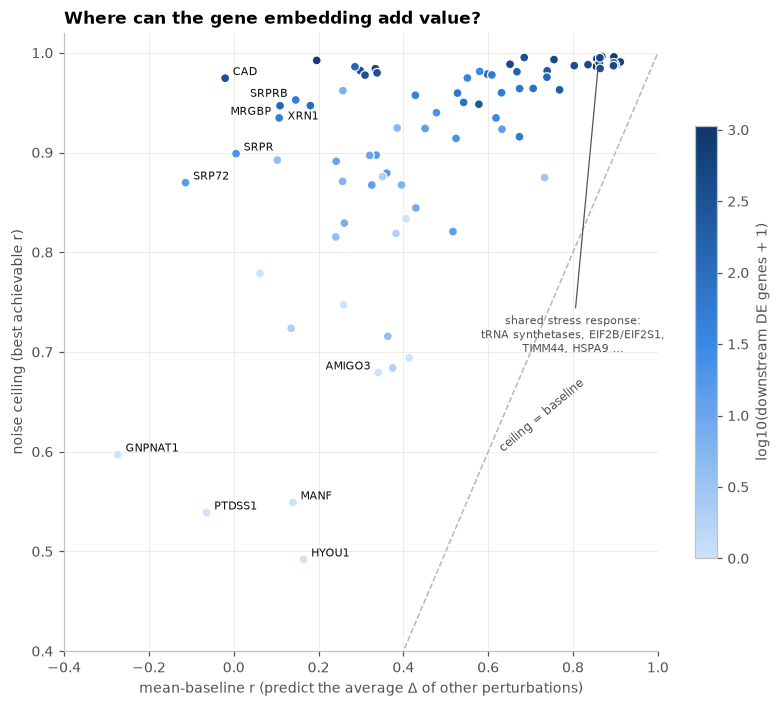

                 count   mean    std    min    25%    50%    75%    max
noise_ceiling     82.0  0.905  0.116  0.492  0.872  0.952  0.984  0.996
mean_baseline_r   82.0  0.478  0.289 -0.273  0.267  0.440  0.726  0.911
headroom          82.0  0.426  0.241  0.079  0.242  0.405  0.585  0.995


In [36]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([-0.4, 1], [-0.4, 1], color=NEUTRAL, lw=1, ls="--", zorder=1)
ax.annotate("ceiling = baseline", (0.62, 0.6), rotation=40, color=INK2, fontsize=8)
sc_ = ax.scatter(ps.mean_baseline_r, ps.noise_ceiling, c=np.log10(ps.n_de_downstream + 1),
                 cmap=LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#3987e5", "#0d366b"]),
                 s=34, edgecolor="white", lw=0.8, zorder=2)
fig.colorbar(sc_, ax=ax, shrink=0.7, label="log10(downstream DE genes + 1)")
ax.set_xlabel("mean-baseline r (predict the average Δ of other perturbations)")
ax.set_ylabel("noise ceiling (best achievable r)")
ax.set_xlim(-0.4, 1); ax.set_ylim(0.4, 1.02)
ax.set_title("Where can the gene embedding add value?")
ax.annotate("shared stress response:\ntRNA synthetases, EIF2B/EIF2S1,\nTIMM44, HSPA9 …", xy=(0.86, 0.99),
            xytext=(0.8, 0.7), fontsize=7.5, color=INK2, ha="center",
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
plt.tight_layout()
label = ps.loc[ps.nlargest(7, "headroom").index.union(ps.nsmallest(5, "noise_ceiling").index)]
place_labels(ax, label.mean_baseline_r, label.noise_ceiling, label.index,
             avoid=(ps.mean_baseline_r, ps.noise_ceiling))
plt.show()

print(ps[["noise_ceiling", "mean_baseline_r", "headroom"]].describe().round(3).T)

In [37]:
cols = ["n_cells", "n_de_downstream", "on_target_delta", "effect_l2",
        "noise_ceiling", "mean_baseline_r", "headroom"]
print("Easiest for the mean baseline (little left to learn):")
display(ps.nlargest(8, "mean_baseline_r")[cols].round(3))
print("Most headroom (the embedding must carry the prediction):")
display(ps.nlargest(8, "headroom")[cols].round(3))

Easiest for the mean baseline (little left to learn):


,n_cells,n_de_downstream,on_target_delta,effect_l2,noise_ceiling,mean_baseline_r,headroom
gene,,,,,,,
TIMM44,586,610,-0.349,6.011,0.991,0.911,0.079
SARS1,470,855,-0.553,6.911,0.990,0.907,0.083
QARS1,378,769,-0.327,7.077,0.989,0.907,0.082
EIF2B3,412,608,-0.550,6.439,0.988,0.899,0.089
CARS1,499,1069,-0.236,8.793,0.994,0.898,0.096
IARS2,1103,791,-0.295,6.756,0.996,0.896,0.100
EIF2B2,612,527,-0.192,5.642,0.990,0.896,0.094
FARSB,625,434,-0.453,4.847,0.987,0.895,0.092


Most headroom (the embedding must carry the prediction):


,n_cells,n_de_downstream,on_target_delta,effect_l2,noise_ceiling,mean_baseline_r,headroom
gene,,,,,,,
CAD,280,347,-0.133,4.901,0.975,-0.020,0.995
SRP72,509,14,-0.776,1.670,0.870,-0.114,0.984
SRPR,581,21,-0.215,1.807,0.899,0.005,0.893
GNPNAT1,494,0,-0.158,1.021,0.597,-0.273,0.870
XRN1,774,135,-0.107,2.220,0.947,0.109,0.838
MRGBP,564,48,-0.234,2.174,0.935,0.107,0.828
SRPRB,699,48,-0.360,2.412,0.953,0.146,0.807
PSMD4,612,717,-0.937,6.041,0.992,0.196,0.797


## 19. How many independent response patterns? PCA of Δ profiles

If a few principal components explain most of the variance of the 82 Δ profiles, the targets are
**low-rank**: there are a few response programs, and each perturbation is a mix of them. Ridge
regression (X ≈ Gθ) then mainly has to predict a handful of program weights from the embedding.

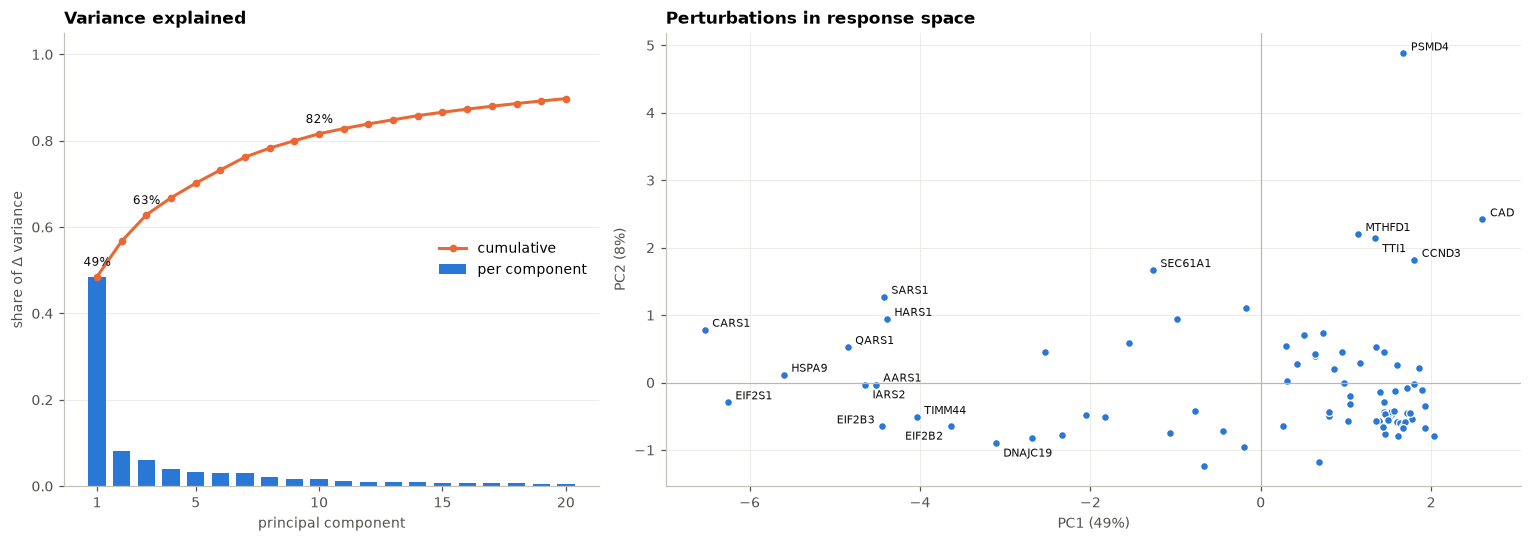

,PC1,PC2,PC3
0,HBZ (+0.28),HBZ (+0.23),SDF2L1 (+0.33)
1,HBG2 (+0.17),HBG2 (+0.15),HSP90B1 (+0.33)
2,HIST1H1C (+0.15),ALAS2 (+0.13),CALR (+0.24)
3,HBG1 (+0.13),BLVRB (+0.13),MANF (+0.24)
4,HBA1 (+0.13),DDIT4 (-0.11),PDIA6 (+0.20)
5,PHGDH (-0.12),LDHA (-0.10),PDIA3 (+0.19)
6,MS4A4A (+0.12),ENO1 (-0.09),PPIB (+0.18)
7,HIST1H2BK (+0.11),HBG1 (+0.09),PDIA4 (+0.16)


In [38]:
pca = PCA().fit(delta.to_numpy())
evr = pca.explained_variance_ratio_
scores = pca.transform(delta.to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
k = 20
ax.bar(range(1, k + 1), evr[:k], color=BLUE, width=0.7, label="per component")
ax.plot(range(1, k + 1), np.cumsum(evr[:k]), color=ORANGE, lw=2, marker="o", ms=4, label="cumulative")
for n in (1, 3, 10):
    ax.annotate(f"{np.cumsum(evr)[n - 1]:.0%}", (n, np.cumsum(evr)[n - 1]), xytext=(0, 7),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xlabel("principal component"); ax.set_ylabel("share of Δ variance")
ax.set_ylim(0, 1.05); ax.set_xticks([1, 5, 10, 15, 20]); ax.grid(axis="x", visible=False)
ax.legend(loc="center right"); ax.set_title("Variance explained")

ax = axes[1]
ax.axhline(0, color=NEUTRAL, lw=0.8); ax.axvline(0, color=NEUTRAL, lw=0.8)
ax.scatter(scores[:, 0], scores[:, 1], s=26, c=BLUE, edgecolor="white", lw=0.8)
ax.set_xlabel(f"PC1 ({evr[0]:.0%})"); ax.set_ylabel(f"PC2 ({evr[1]:.0%})")
ax.set_title("Perturbations in response space")
plt.tight_layout()
far = np.argsort(-np.hypot(scores[:, 0] / scores[:, 0].std(), scores[:, 1] / scores[:, 1].std()))[:18]
place_labels(ax, scores[far, 0], scores[far, 1], delta.index[far], avoid=(scores[:, 0], scores[:, 1]))
plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=delta.columns, columns=["PC1", "PC2", "PC3"])
pd.DataFrame({pc: [f"{gname} ({loadings.loc[gname, pc]:+.2f})"
                   for gname in loadings[pc].abs().nlargest(8).index] for pc in loadings})

## 20. Save the statistics

In [39]:
genes_stats.to_csv(PROCESSED / "readout_gene_stats.csv")
pert_stats.to_csv(PROCESSED / "perturbation_stats.csv")
with open(PROCESSED / "top20_de_genes.json", "w") as f:
    json.dump({c.replace("+ctrl", ""): v for c, v in top20.items()}, f, indent=1)
for name in ["readout_gene_stats.csv", "perturbation_stats.csv", "top20_de_genes.json"]:
    print("Wrote", PROCESSED / name)

Wrote /Users/vuhta/ML_Life_Sciences/data/processed/readout_gene_stats.csv
Wrote /Users/vuhta/ML_Life_Sciences/data/processed/perturbation_stats.csv
Wrote /Users/vuhta/ML_Life_Sciences/data/processed/top20_de_genes.json


## Analysis takeaways

1. **Half of the readout genes carry almost no signal.** 47 % of the 5,062 genes are detected in
   < 10 % of control cells; their median mean |Δ| is 0.002, against 0.09 for well-detected genes,
   and only 11 % of them are DE in any perturbation. A Pearson Δ over all genes therefore partly
   correlates noise. **Report metrics on the top-20 DE genes too** (`top20_de_genes.json`), and
   consider a detection-filtered gene set as a robustness check.
2. **One dominant response program.** PC1 explains 49 % of the Δ variance (top 3: 63 %, top 10: 82 %).
   It is the shared stress response of the tRNA-synthetase, translation-initiation (EIF2B*, EIF2S1)
   and mitochondrial (TIMM44, HSPA9) knockdowns: hemoglobin and histone genes go down, PHGDH and
   related genes go up. A second, separate program is the **UPR / ER chaperone** response (HSPA5,
   HSP90B1, SDF2L1, CALR, MANF, PDIA6 up; PC3), driven by ER translocation and glycosylation
   knockdowns (e.g. DHDDS, SEL1L, SCYL1, IER3IP1).
3. **The "predict the mean" baseline is strong and uneven.** The leave-one-out mean Δ already reaches
   a median Pearson r of 0.44, and ≈ 0.9 for the stress-response cluster. A model's average Pearson Δ
   must be **compared against this baseline**, not against 0.
4. **The data are reliable enough to tell models apart.** The median noise ceiling is 0.95. It is
   low only for near-null perturbations (HYOU1, PTDSS1, MANF, GNPNAT1: ceiling 0.49–0.6).
5. **24 / 82 perturbations are near-null** (< 10 downstream DE genes). The DE count does not depend on
   cell count (Spearman ρ = −0.09), so this is biology, not missing power. Report results stratified
   by effect size; averages over all 82 mix two very different regimes.
6. **Where embeddings must earn their keep:** perturbations with a real effect but a response unlike
   the average, e.g. CAD, SRP72, SRPR, SRPRB, XRN1, MRGBP and PSMD4 (`headroom` ≈ 0.8 or more in
   `perturbation_stats.csv`). These are the most informative test cases for GenePT vs. random
   embeddings.